# Volume Test

Pertanyaan yang ingin dijawab notebook ini sederhana: **kalau datanya makin besar, apakah query kita masih cukup cepat?**

Untuk menjawabnya, setiap query (R1–R10 untuk read dan W1–W10 untuk write) dijalankan di tiga ukuran data:
- **small:** 10 ribu order
- **medium:** 100 ribu order
- **large:** 1 juta order

Di setiap ukuran, query dijalankan sekali untuk pemanasan, lalu lima kali lagi untuk diukur waktunya. Query dijalankan satu per satu, jadi yang kita lihat murni pengaruh ukuran data, bukan pengaruh banyaknya pengguna yang mengakses bersamaan.

Supaya pengukurannya bersih, ada dua langkah persiapan:
- **Sebelum benchmark dimulai:** database dibersihkan dengan `VACUUM (ANALYZE)`, sehingga proses perawatan otomatis PostgreSQL tidak berjalan di tengah pengukuran.
- **Sebelum setiap query:** `CHECKPOINT` dijalankan untuk menuntaskan pekerjaan tulis ke disk yang tertunda.

Kelima run kemudian dijalankan berurutan tanpa jeda, karena jeda justru membuat CPU melambat dan run berikutnya terukur lebih lama.

Hasilnya kita baca dari dua sudut:
- **Load test:** apakah semua query cukup cepat di ukuran data normal (small dan medium)?
- **Stress test:** apa yang terjadi di ukuran data besar (large)? Query mana yang mulai berat, kenapa, dan kira-kira di ukuran berapa batasnya akan terlewati?

Setelah itu kita cek apakah angka-angkanya bisa dipercaya, lewat standar deviasi dan error rate.

In [1]:
import json
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter

pd.set_option('display.max_colwidth', None)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
RESULTS = ROOT / 'results'
PROFILES = ['small', 'medium', 'large']
QUERY_ORDER = [f'R{i}' for i in range(1, 11)] + [f'W{i}' for i in range(1, 11)]


def latest(pattern: str) -> Path:
    files = sorted(RESULTS.glob(pattern))
    if not files:
        raise FileNotFoundError(f'Tidak ada file {pattern} di {RESULTS}')
    return files[-1]


def category(query: str) -> str:
    if query == 'R10':
        return 'Operasional'
    return 'Transaksional' if query.startswith('W') else 'Analitik'


def plan_facts(plans: list[list[str]]) -> dict:
    # Baris Buffers pertama di setiap plan adalah total untuk statement itu.
    text = '\n'.join('\n'.join(plan) for plan in plans)
    read = temp = 0
    for plan in plans:
        for line in plan:
            match = re.search(r'Buffers: shared(?: hit=(\d+))?(?: read=(\d+))?(?:.*?temp(?: read=\d+)? written=(\d+))?',
                              line)
            if match:
                read += int(match[1] or 0) + int(match[2] or 0)
                temp += int(match[3] or 0)
                break
    return {
        'seq_scan': ', '.join(sorted(set(re.findall(r'Seq Scan on (\w+)', text)))) or '-',
        'index_scans': len(re.findall(r'Index (?:Only )?Scan', text)),
        'workers': max([int(n) for n in re.findall(r'Workers Launched: (\d+)', text)] or [0]),
        'data_read_mb': round(read * 8 / 1024, 1),
        'temp_written_mb': round(temp * 8 / 1024, 1),
    }


config = yaml.safe_load((ROOT / 'config' / 'dataset_profile.yaml').read_text())
ORDERS = {p: config['profiles'][p]['service_orders'] for p in PROFILES}

rows, meta, EXECUTIONS, TIMED_RUNS = [], [], {}, {}
for profile in PROFILES:
    path = latest(f'{profile}_*.json')
    data = json.loads(path.read_text())
    EXECUTIONS[profile] = data['warmup_runs'] + data['timed_runs']
    TIMED_RUNS[profile] = data['timed_runs']
    meta.append({
        'profil': profile,
        'service orders': f'{ORDERS[profile]:,}',
        'file hasil': path.name,
        'PostgreSQL': data['postgres_version'].split()[0],
        'mulai (UTC)': data['started_at'],
        'warm-up + run': f"{data['warmup_runs']} + {data['timed_runs']}",
        'host': f"{data['host']['platform'].split('-')[0]}, {data['host']['cpu_count']} CPU",
    })
    for query in data['queries']:
        rows.append({'profile': profile, 'query': query['query'], 'title': query['title'],
                     'median_ms': query['median_ms'], 'min_ms': query['min_ms'], 'max_ms': query['max_ms'],
                     'mean_ms': query['mean_ms'], 'stdev_ms': query['stdev_ms'], 'rows': query['rows'],
                     'times_ms': query['times_ms'], 'rows_per_run': query['rows_per_run'],
                     **plan_facts(query['plans'])})

bench = pd.DataFrame(rows)
bench['category'] = bench['query'].map(category)
bench['orders'] = bench['profile'].map(ORDERS)
bench['cv_pct'] = 100 * bench['stdev_ms'] / bench['mean_ms']
bench['profile'] = pd.Categorical(bench['profile'], PROFILES, ordered=True)
bench['query'] = pd.Categorical(bench['query'], QUERY_ORDER, ordered=True)
bench = bench.sort_values(['profile', 'query']).reset_index(drop=True)

distribution = ', '.join(f'{kind} {share:.0%}' for kind, share in config['order_distribution'].items())
display(Markdown(f'**Distribusi order:** {distribution}. **Jumlah query:** {bench["query"].nunique()} per profil.'))
display(pd.DataFrame(meta).set_index('profil'))

**Distribusi order:** mobility 32%, food 32%, delivery 36%. **Jumlah query:** 20 per profil.

,service orders,file hasil,PostgreSQL,mulai (UTC),warm-up + run,host
profil,,,,,,
small,"10,000",small_20261104-162655.json,17.11,2026-11-04T09:26:48+00:00,1 + 5,"macOS, 10 CPU"
medium,"100,000",medium_20261104-162711.json,17.11,2026-11-04T09:26:57+00:00,1 + 5,"macOS, 10 CPU"
large,"1,000,000",large_20261104-162812.json,17.11,2026-11-04T09:27:13+00:00,1 + 5,"macOS, 10 CPU"


In [2]:
INK, INK_2, MUTED = '#0b0b0b', '#52514e', '#898781'
SURFACE, GRID, AXIS = '#fcfcfb', '#e1e0d9', '#c3c2b7'
BACKGROUND = '#c3c2b7'
BLUE, ORANGE = '#2a78d6', '#eb6834'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.family': 'sans-serif', 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'legend.frameon': False, 'legend.fontsize': 9,
})
PLAIN = FuncFormatter(lambda v, _: f'{v:,.0f}' if v >= 1 else f'{v:g}')

In [3]:
def dec(value, digits=1):
    return f'{value:.{digits}f}'.replace('.', ',')


def ms_text(ms):
    if ms >= 1000:
        return dec(ms / 1000).removesuffix(',0') + ' detik'
    if ms >= 10:
        return f'{ms:,.0f}'.replace(',', '.') + ' ms'
    return dec(ms) + ' ms'


def orders_text(n):
    return dec(n / 1e6) + ' juta order'


def names(items):
    items = [str(i) for i in items]
    return items[0] if len(items) == 1 else ', '.join(items[:-1]) + ' dan ' + items[-1]


def say(text):
    display(Markdown(text))

## 1. Ringkasan hasil

Tabel di bawah berisi waktu median dari lima run, dalam milidetik. Median adalah nilai tengah, jadi satu run yang kebetulan lambat tidak mengubah gambaran keseluruhan.
- **Write dengan beberapa statement:** waktunya adalah total semua statement.
- **Kolom `baris`:** berapa baris yang dikembalikan oleh read, atau yang diubah oleh write.

In [4]:
summary = bench.pivot_table(index=['category', 'query'], columns='profile', values='median_ms', observed=True).round(2)
summary.columns = [f'median {p} (ms)' for p in summary.columns]
rows_table = bench.pivot_table(index=['category', 'query'], columns='profile', values='rows', observed=True)
summary[[f'baris {p}' for p in PROFILES]] = rows_table[PROFILES].astype(int).values
summary.index.names = ['kategori', 'query']
display(summary)

median small (ms)  median medium (ms)  median large (ms)  \
kategori      query                                                             
Analitik      R1                  6.95               53.51             605.87   
              R2                  7.94               73.49            1041.01   
              R3                 20.38              271.42            1553.20   
              R4                  6.12               63.01             603.87   
              R5                  3.49               35.82             149.43   
              R6                 10.22              121.65             849.36   
              R7                  6.76               85.99             531.24   
              R8                  6.15              100.08             584.22   
              R9                  1.94               14.00             103.32   
Operasional   R10                 0.35                0.93               6.22   
Transaksional W1                  4.50                7.28              19.61   
              W2                  1.01                0.81               0.96   
              W3                  1.02                1.17               1.73   
              W4                  3.05                3.69              12.75   
              W5                  1.44                1.56               1.99   
              W6                  1.67                1.38               1.76   
              W7                  3.20                3.03               3.48   
              W8                  1.49                1.37               1.76   
              W9                  2.05                2.45               2.24   
              W10                 1.36                4.59              45.74   

                     baris small  baris medium  baris large  
kategori      query                                          
Analitik      R1             497          4984        49862  
              R2              10            10           10  
              R3             144           144          144  
              R4            1359         13083       129895  
              R5              23            23           23  
              R6              23            23           23  
              R7              24            25           27  
              R8              10            10           10  
              R9              23            23           23  
Operasional   R10             10            20           20  
Transaksional W1               4             4            4  
              W2               1             1            1  
              W3               3             3            3  
              W4               6             6            6  
              W5               3             3            3  
              W6               6             6            6  
              W7               8             8            8  
              W8               3             3            3  
              W9               7             7            7  
              W10              3             3            3

Grafik di bawah menampilkan angka yang sama secara visual: waktu median setiap query di ketiga ukuran data.
- **Warna batang:** semakin gelap, semakin besar datanya (small, medium, large).
- **Sumbu tegak:** memakai skala log, karena waktunya berkisar dari kurang dari 1 ms sampai lebih dari 1 detik. Pada skala log, setiap garis bantu berarti 10 kali lebih lama dari garis di bawahnya.
- **Garis kecil di setiap batang:** rentang dari run tercepat sampai run terlambat di antara 5 run. Garis yang pendek berarti waktunya konsisten.

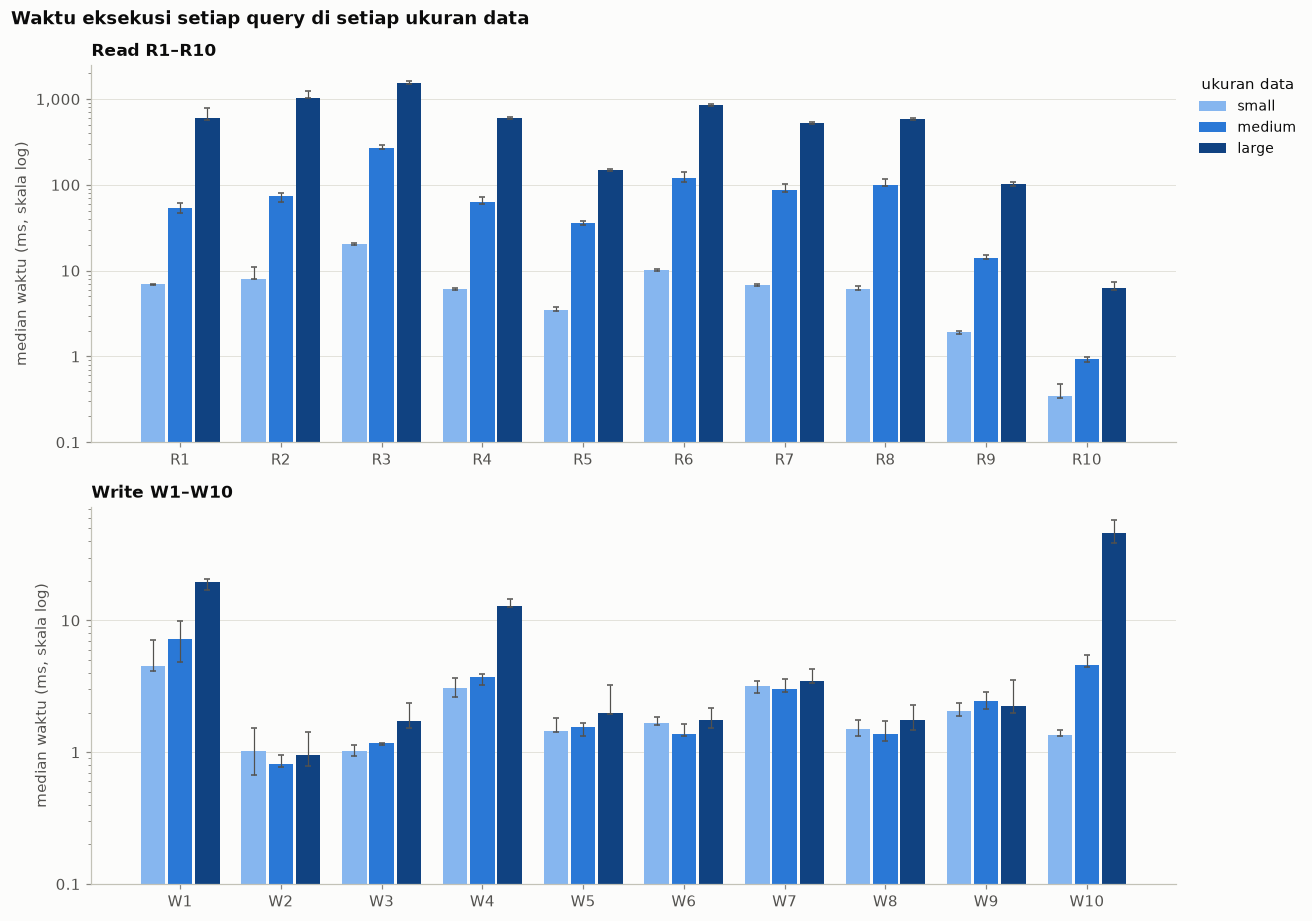

In [5]:
PROFILE_COLORS = {'small': '#86b6ef', 'medium': '#2a78d6', 'large': '#104281'}
width = 0.27
fig, axes = plt.subplots(2, 1, figsize=(12, 8.5))
for ax, prefix, title in [(axes[0], 'R', 'Read R1–R10'), (axes[1], 'W', 'Write W1–W10')]:
    queries = [q for q in QUERY_ORDER if q.startswith(prefix)]
    for i, profile in enumerate(PROFILES):
        frame = bench[bench['profile'] == profile].set_index(bench.loc[bench['profile'] == profile, 'query']
                                                            .astype(str)).loc[queries]
        xs = [k + (i - 1) * width for k in range(len(queries))]
        ax.bar(xs, frame['median_ms'], width=width * 0.9, color=PROFILE_COLORS[profile], label=profile, zorder=2)
        ax.errorbar(xs, frame['median_ms'], yerr=[frame['median_ms'] - frame['min_ms'],
                                                  frame['max_ms'] - frame['median_ms']],
                    fmt='none', ecolor=INK_2, elinewidth=0.8, capsize=2, zorder=3)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(PLAIN)
    ax.set_ylim(bottom=0.1)
    ax.set_xticks(range(len(queries)), labels=queries)
    ax.grid(axis='x', visible=False)
    ax.set_ylabel('median waktu (ms, skala log)')
    ax.set_title(title)
axes[0].legend(title='ukuran data', loc='upper left', bbox_to_anchor=(1.01, 1.0))
fig.suptitle('Waktu eksekusi setiap query di setiap ukuran data', x=0.01, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

In [6]:
medians = bench.pivot_table(index='query', columns='profile', values='median_ms', observed=True)
growth = (medians['large'] / medians['small']).rename(index=str)
steep = growth[growth >= 10].sort_values(ascending=False)
flat = growth[growth < 2]
say('Dari grafik ini terlihat dua kelompok yang jelas:\n'
    f'- **Batangnya naik tajam dari small ke large:** {names(steep.index)}. Waktunya bertambah '
    f'{growth[steep.index].min():.0f}–{growth[steep.index].max():.0f} kali saat data 100 kali lebih besar. '
    'Hampir semuanya query analitik, yang memang harus membaca seluruh data.\n'
    f'- **Batangnya hampir sama tinggi di ketiga ukuran data:** {names(flat.index)}. Waktunya bertambah kurang dari '
    '2 kali, karena query ini langsung menuju baris yang dicari lewat index.')

Dari grafik ini terlihat dua kelompok yang jelas:
- **Batangnya naik tajam dari small ke large:** R2, R4, R8, R1, R6, R7, R3, R9, R5, W10 dan R10. Waktunya bertambah 18–131 kali saat data 100 kali lebih besar. Hampir semuanya query analitik, yang memang harus membaca seluruh data.
- **Batangnya hampir sama tinggi di ketiga ukuran data:** W2, W3, W5, W6, W7, W8 dan W9. Waktunya bertambah kurang dari 2 kali, karena query ini langsung menuju baris yang dicari lewat index.

## 2. Target waktu

Sebelum menilai cepat atau lambat, kita perlu patokan. Tidak ada standar resmi untuk ini, jadi kita pakai patokan yang umum untuk aplikasi interaktif:

| Kategori | Target | Kenapa |
|---|---|---|
| Operasional (R10) | ≤ 100 ms | Dipanggil langsung saat pengguna membuka layar. Respons di bawah 0,1 detik terasa instan. Selain itu, query database hanya sebagian dari total waktu satu request ke server, yang biasanya 200–500 ms. |
| Transaksional (W1–W10) | ≤ 200 ms | Setiap write adalah satu aksi bisnis, seperti checkout atau pembatalan, yang terdiri dari beberapa statement. Wajar kalau sedikit lebih lama dari satu pencarian. 200 ms juga masih di kisaran normal: banyak tim baru menandai query sebagai "lambat" kalau di atas 100–500 ms. |
| Analitik (R1–R9) | ≤ 2 detik | Untuk laporan atau dashboard yang dibuka sesekali. Menunggu 1–3 detik masih nyaman, tetapi di atas sekitar 10 detik orang mulai kehilangan fokus. |

Sebuah query kita anggap lulus kalau run paling lambatnya masih di bawah target. Sengaja dipakai run paling lambat, bukan median, supaya kesimpulannya tetap berlaku untuk kasus terburuk yang kita lihat.

In [7]:
SLO_MS = {'Operasional': 100, 'Transaksional': 200, 'Analitik': 2000}
bench['slo_ms'] = bench['category'].map(SLO_MS)
bench['passes'] = bench['max_ms'] <= bench['slo_ms']


def verdict_table(profiles):
    frame = bench[bench['profile'].isin(profiles)].copy()
    frame['hasil'] = [f"{'✓' if ok else '✗'} {worst:,.1f} ms" for ok, worst in zip(frame['passes'], frame['max_ms'])]
    table = frame.pivot_table(index=['category', 'query'], columns='profile', values='hasil', aggfunc='first',
                              observed=True)
    table.index.names = ['kategori', 'query']
    table.columns = [f'{p} (run terlambat)' for p in table.columns]
    passed = frame.groupby('profile', observed=True)['passes'].agg(['sum', 'count'])
    return table, ', '.join(f'{p} {int(r["sum"])}/{int(r["count"])}' for p, r in passed.iterrows())

## 3. Load test: ukuran data normal

Di small dan medium, harapannya semua query lulus dengan mudah. Angka di tabel adalah run paling lambat dari lima run.

In [8]:
table, passed = verdict_table(['small', 'medium'])
display(table)
display(Markdown(f'**Lulus:** {passed}'))

small (run terlambat) medium (run terlambat)
kategori      query                                             
Analitik      R1                 ✓ 7.1 ms              ✓ 60.8 ms
              R2                ✓ 10.9 ms              ✓ 80.7 ms
              R3                ✓ 20.8 ms             ✓ 290.0 ms
              R4                 ✓ 6.3 ms              ✓ 72.9 ms
              R5                 ✓ 3.7 ms              ✓ 37.8 ms
              R6                ✓ 10.4 ms             ✓ 142.0 ms
              R7                 ✓ 7.1 ms             ✓ 102.6 ms
              R8                 ✓ 6.6 ms             ✓ 116.9 ms
              R9                 ✓ 2.0 ms              ✓ 15.1 ms
Operasional   R10                ✓ 0.5 ms               ✓ 1.0 ms
Transaksional W1                 ✓ 7.1 ms               ✓ 9.9 ms
              W2                 ✓ 1.5 ms               ✓ 1.0 ms
              W3                 ✓ 1.1 ms               ✓ 1.2 ms
              W4                 ✓ 3.6 ms               ✓ 3.9 ms
              W5                 ✓ 1.8 ms               ✓ 1.7 ms
              W6                 ✓ 1.8 ms               ✓ 1.6 ms
              W7                 ✓ 3.4 ms               ✓ 3.6 ms
              W8                 ✓ 1.7 ms               ✓ 1.7 ms
              W9                 ✓ 2.4 ms               ✓ 2.9 ms
              W10                ✓ 1.5 ms               ✓ 5.5 ms

**Lulus:** small 20/20, medium 20/20

In [9]:
normal = bench[bench['profile'].isin(['small', 'medium'])]
failed_normal = normal[~normal['passes']]
medium_rows = bench[bench['profile'] == 'medium']
slowest = medium_rows.loc[medium_rows['max_ms'].idxmax()]
write_max = normal.loc[normal['category'] == 'Transaksional', 'max_ms'].max()
opening = ('Hasilnya sesuai harapan: semua lulus.' if failed_normal.empty else
           'Tidak semuanya lulus: ' + names(f"{r['query']} di {r['profile']}" for _, r in failed_normal.iterrows())
           + ' melewati targetnya.')
say(f"{opening}\n"
    f"- **Query paling lambat di medium:** {slowest['query']}, dengan {ms_text(slowest['max_ms'])}, "
    f"dari batas {ms_text(slowest['slo_ms'])}.\n"
    f"- **Semua write:** selesai dalam paling lama {ms_text(write_max)}.")

Hasilnya sesuai harapan: semua lulus.
- **Query paling lambat di medium:** R3, dengan 290 ms, dari batas 2 detik.
- **Semua write:** selesai dalam paling lama 9,9 ms.

## 4. Stress test: ukuran data besar

Di large, datanya 100 kali lebih besar dari small. Di sini kita tidak hanya bertanya lulus atau tidak, tetapi juga seberapa cepat waktunya bertambah:
- **Kolom `medium → large`:** berapa kali lebih lambat sebuah query saat datanya naik 10 kali.
- **Kolom `eksponen b`:** merangkum pola pertumbuhan menjadi satu angka, lewat model waktu ∝ (jumlah order)ᵇ.
  - **Cara menghitung:** b diperoleh dari regresi linier pada skala log-log atas ke-15 run (5 run × 3 ukuran data), bukan hanya dari median.
  - **Cara membaca:** kalau b mendekati 0, waktunya hampir tidak terpengaruh ukuran data. Kalau mendekati 1, data 10 kali lebih besar membuat query 10 kali lebih lambat.
  - **Angka ± di belakangnya:** interval kepercayaan 95%, yaitu seberapa yakin kita pada nilai b.
- **Kolom `R²`:** seberapa baik model itu menjelaskan data. Nilai mendekati 1 berarti pertumbuhannya memang mengikuti pola tersebut. Pada query yang waktunya konstan, R² wajar rendah, karena tidak ada tren yang bisa dijelaskan, hanya variasi kecil antar-run.

In [10]:
wide = bench.pivot_table(index='query', columns='profile', values='median_ms', observed=True)
import numpy as np

# Regresi log-log: log10(waktu) = a + b * log10(jumlah order), memakai setiap run (bukan hanya median).
T_975 = {8: 2.306, 10: 2.228, 13: 2.160, 16: 2.120, 18: 2.101, 28: 2.048}
fits = {}
for query, group in bench.groupby('query', observed=True):
    x = np.concatenate([[math.log10(n)] * len(times) for n, times in zip(group['orders'], group['times_ms'])])
    y = np.log10(np.concatenate(list(group['times_ms'])))
    slope, intercept = np.polyfit(x, y, 1)
    residual = y - (intercept + slope * x)
    ss_res, ss_tot = (residual ** 2).sum(), ((y - y.mean()) ** 2).sum()
    df = len(x) - 2
    se = math.sqrt(ss_res / df / ((x - x.mean()) ** 2).sum())
    fits[str(query)] = {'b': slope, 'ci': T_975.get(df, 1.96) * se, 'r2': 1 - ss_res / ss_tot, 'n': len(x)}
exponent = pd.Series({q: f['b'] for q, f in fits.items()})
large = bench[bench['profile'] == 'large'].set_index('query')
stress = pd.DataFrame({
    'kategori': large['category'],
    'median large (ms)': large['median_ms'].round(1),
    'run terlambat (ms)': large['max_ms'].round(1),
    'target (ms)': large['slo_ms'],
    'hasil': large['passes'].map({True: '✓ lulus', False: '✗ gagal'}),
    'medium → large': (wide['large'] / wide['medium']).map('{:.1f}×'.format),
    'eksponen b (± interval kepercayaan 95%)': [f"{fits[str(q)]['b']:.2f} ± {fits[str(q)]['ci']:.2f}" for q in large.index],
    'R² (kecocokan model)': [round(fits[str(q)]['r2'], 2) for q in large.index],
})
display(stress.loc[[q for q in QUERY_ORDER if q in stress.index]])
display(Markdown(f"**Lulus di large:** {int(large['passes'].sum())}/{len(large)}"))

,kategori,median large (ms),run terlambat (ms),target (ms),hasil,medium → large,eksponen b (± interval kepercayaan 95%),R² (kecocokan model)
query,,,,,,,,
R1,Analitik,605.9,794.0,2000,✓ lulus,11.3×,0.98 ± 0.04,0.99
R2,Analitik,1041.0,1240.9,2000,✓ lulus,14.2×,1.05 ± 0.05,0.99
R3,Analitik,1553.2,1626.2,2000,✓ lulus,5.7×,0.94 ± 0.07,0.99
R4,Analitik,603.9,620.2,2000,✓ lulus,9.6×,1.00 ± 0.02,1.00
R5,Analitik,149.4,154.3,2000,✓ lulus,4.2×,0.81 ± 0.07,0.98
R6,Analitik,849.4,867.4,2000,✓ lulus,7.0×,0.96 ± 0.04,0.99
R7,Analitik,531.2,538.2,2000,✓ lulus,6.2×,0.95 ± 0.06,0.99
R8,Analitik,584.2,594.6,2000,✓ lulus,5.8×,0.98 ± 0.08,0.98
R9,Analitik,103.3,106.9,2000,✓ lulus,7.4×,0.87 ± 0.01,1.00


**Lulus di large:** 20/20

In [11]:
large_rows = bench[bench['profile'] == 'large']
failed_large = large_rows[~large_rows['passes']]
if failed_large.empty:
    opening = f'Ke-{len(large_rows)} query masih lulus di large, tetapi tidak semuanya dengan nyaman.'
else:
    opening = (f'{len(large_rows) - len(failed_large)} dari {len(large_rows)} query lulus di large. Yang gagal: '
               + names(f"{r['query']} ({ms_text(r['max_ms'])})" for _, r in failed_large.iterrows()) + '.')
say(opening + ' Grafik di bawah menunjukkan seberapa dekat setiap query ke batasnya, di ketiga ukuran data.\n'
    '- **Posisi titik:** run paling lambat, sebagai persen dari target.\n'
    '- **Garis 100%:** batas target. Titik di sebelah kanannya berarti gagal.\n'
    '- **Sumbu:** memakai skala log, karena ada query yang hanya memakai sebagian kecil dari targetnya.')

Ke-20 query masih lulus di large, tetapi tidak semuanya dengan nyaman. Grafik di bawah menunjukkan seberapa dekat setiap query ke batasnya, di ketiga ukuran data.
- **Posisi titik:** run paling lambat, sebagai persen dari target.
- **Garis 100%:** batas target. Titik di sebelah kanannya berarti gagal.
- **Sumbu:** memakai skala log, karena ada query yang hanya memakai sebagian kecil dari targetnya.

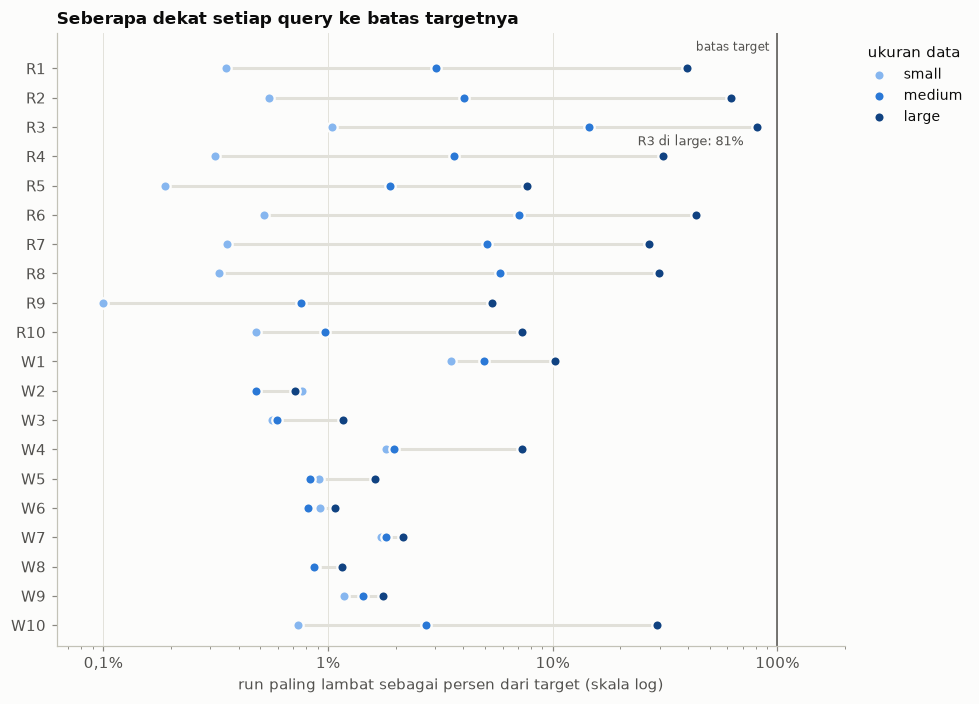

In [12]:
PROFILE_COLORS = {'small': '#86b6ef', 'medium': '#2a78d6', 'large': '#104281'}
usage = bench.assign(pct=100 * bench['max_ms'] / bench['slo_ms'])
order = list(reversed(QUERY_ORDER))
fig, ax = plt.subplots(figsize=(9, 6.5))
for y, query in enumerate(order):
    values = usage[usage['query'] == query].set_index('profile')['pct']
    ax.plot([values.min(), values.max()], [y, y], color=GRID, lw=2, zorder=1)
    for profile in PROFILES:
        ax.scatter(values[profile], y, s=46, color=PROFILE_COLORS[profile], edgecolor=SURFACE, lw=1.5, zorder=3,
                   label=profile if y == 0 else None)
ax.axvline(100, color=INK_2, lw=1, zorder=2)
ax.annotate('batas target', (100, len(order) - 0.4), xytext=(-5, 0), textcoords='offset points', ha='right',
            fontsize=8, color=INK_2)
top = usage.loc[usage['pct'].idxmax()]
ax.annotate(f"{top['query']} di {top['profile']}: {top['pct']:.0f}%".replace('.', ','),
            (top['pct'], order.index(str(top['query']))), xytext=(-9, -12), textcoords='offset points',
            ha='right', fontsize=8.5, color=INK_2)
ax.set_xscale('log')
ax.set_xlim(min(0.1, usage['pct'].min() / 1.6), 200)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}%'.replace('.', ',')))
ax.set_yticks(range(len(order)), labels=order)
ax.set_ylim(-0.7, len(order) + 0.2)
ax.grid(axis='y', visible=False)
ax.set_xlabel('run paling lambat sebagai persen dari target (skala log)')
ax.set_title('Seberapa dekat setiap query ke batas targetnya')
ax.legend(title='ukuran data', loc='upper left', bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

In [13]:
top = usage.loc[usage['pct'].idxmax()]
analytic_b = exponent[[q for q in exponent.index if category(q) == 'Analitik']]
flat_writes = [q for q in QUERY_ORDER if q.startswith('W') and exponent[q] < 0.2]
say('Semakin besar datanya, semakin ke kanan titiknya.\n'
    f"- **Paling mepet:** {top['query']}, yang di {top['profile']} sudah memakai sekitar {top['pct']:.0f}% "
    'dari targetnya.\n'
    '- **Polanya terbagi dua:**\n'
    f'  - **Query analitik:** b sekitar {dec(analytic_b.min())}–{dec(analytic_b.max())}, artinya waktunya naik '
    'hampir sebanding dengan jumlah data.\n'
    f'  - **{len(flat_writes)} dari 10 write ({names(flat_writes)}):** b mendekati 0, artinya ukuran data hampir '
    'tidak berpengaruh.\n\n'
    'Grafik berikut menggambarkan hal yang sama. Kedua sumbu memakai skala log, jadi makin curam garisnya, makin '
    'peka query itu terhadap ukuran data.\n'
    '- **Panel read:** query analitik digambar abu-abu, dan R10 biru.\n'
    '- **Panel write:** garis oranye adalah write yang waktunya ikut membesar (b > 0,5), sisanya abu-abu.\n'
    '- **Garis horizontal:** batas target.')

Semakin besar datanya, semakin ke kanan titiknya.
- **Paling mepet:** R3, yang di large sudah memakai sekitar 81% dari targetnya.
- **Polanya terbagi dua:**
  - **Query analitik:** b sekitar 0,8–1,0, artinya waktunya naik hampir sebanding dengan jumlah data.
  - **7 dari 10 write (W2, W3, W5, W6, W7, W8 dan W9):** b mendekati 0, artinya ukuran data hampir tidak berpengaruh.

Grafik berikut menggambarkan hal yang sama. Kedua sumbu memakai skala log, jadi makin curam garisnya, makin peka query itu terhadap ukuran data.
- **Panel read:** query analitik digambar abu-abu, dan R10 biru.
- **Panel write:** garis oranye adalah write yang waktunya ikut membesar (b > 0,5), sisanya abu-abu.
- **Garis horizontal:** batas target.

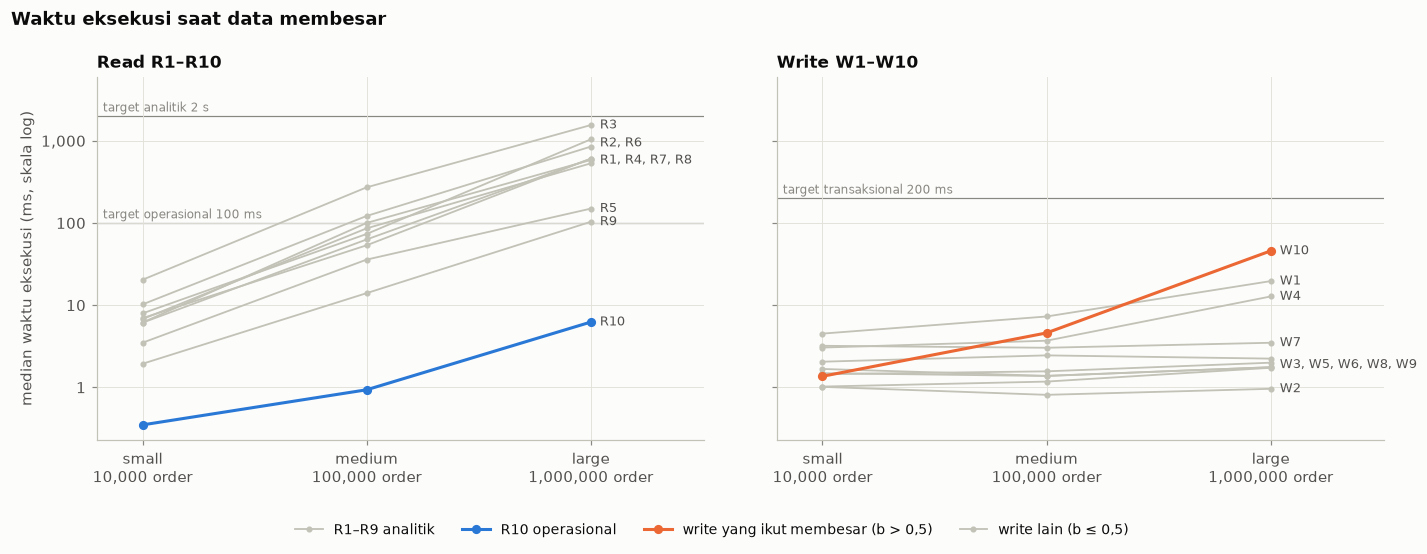

In [14]:
def cluster_labels(ax, frame, value_col, x):
    # Satu label untuk setiap kelompok garis yang ujungnya berdekatan, supaya label tidak bertumpuk.
    ends = frame.sort_values(value_col)
    groups, current = [], []
    for query, value in zip(ends['query'], ends[value_col]):
        if current and value / current[-1][1] > 1.3:
            groups.append(current)
            current = []
        current.append((query, value))
    groups.append(current)
    for group in groups:
        names = ', '.join(sorted((q for q, _ in group), key=QUERY_ORDER.index))
        y = math.exp(sum(math.log(v) for _, v in group) / len(group))
        ax.annotate(names, (x, y), xytext=(6, 0), textcoords='offset points', va='center', fontsize=8.5,
                    color=INK_2)


exp_by_query = exponent.to_dict()
fig, (ax_r, ax_w) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, prefix in [(ax_r, 'R'), (ax_w, 'W')]:
    frame = bench[bench['query'].astype(str).str.startswith(prefix)]
    for query, group in frame.groupby('query', observed=True):
        if prefix == 'R':
            color = BLUE if query == 'R10' else BACKGROUND
        else:
            color = ORANGE if exp_by_query[query] > 0.5 else BACKGROUND
        focus = color != BACKGROUND
        ax.plot(group['orders'], group['median_ms'], color=color, lw=2 if focus else 1.2,
                marker='o', ms=5 if focus else 3, zorder=3 if focus else 2)
    cluster_labels(ax, frame[frame['profile'] == 'large'].astype({'query': str}), 'median_ms', ORDERS['large'])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xticks(list(ORDERS.values()), labels=[f'{p}\n{n:,} order' for p, n in ORDERS.items()])
    ax.minorticks_off()
    ax.yaxis.set_major_formatter(PLAIN)
    ax.set_xlim(ORDERS['small'] / 1.6, ORDERS['large'] * 3.2)
    ax.set_ylim(top=6000)
for ax, slos in [(ax_r, [(2000, 'target analitik 2 s'), (100, 'target operasional 100 ms')]),
                 (ax_w, [(200, 'target transaksional 200 ms')])]:
    for slo, label in slos:
        ax.axhline(slo, color=MUTED, lw=0.8, zorder=1)
        ax.annotate(label, (ORDERS['small'] / 1.6, slo), xytext=(4, 3), textcoords='offset points', fontsize=8,
                    color=MUTED)
ax_r.set_title('Read R1–R10')
ax_w.set_title('Write W1–W10')
ax_r.set_ylabel('median waktu eksekusi (ms, skala log)')
handles = [plt.Line2D([], [], color=BACKGROUND, lw=1.2, marker='o', ms=3, label='R1–R9 analitik'),
           plt.Line2D([], [], color=BLUE, lw=2, marker='o', ms=5, label='R10 operasional'),
           plt.Line2D([], [], color=ORANGE, lw=2, marker='o', ms=5, label='write yang ikut membesar (b > 0,5)'),
           plt.Line2D([], [], color=BACKGROUND, lw=1.2, marker='o', ms=3, label='write lain (b ≤ 0,5)')]
fig.legend(handles=handles, loc='lower center', ncol=4, bbox_to_anchor=(0.5, 0.0))
fig.suptitle('Waktu eksekusi saat data membesar', x=0.01, ha='left', fontsize=12, fontweight='bold')
fig.subplots_adjust(left=0.07, right=0.97, top=0.86, bottom=0.2, wspace=0.12)
plt.show()

Kalau semua query diurutkan berdasarkan eksponen b, terlihat jelas mana yang peka terhadap ukuran data dan mana yang tidak. Garis kecil di ujung batang adalah interval kepercayaan 95%. Interval yang sempit berarti polanya sangat konsisten di ketiga ukuran data.

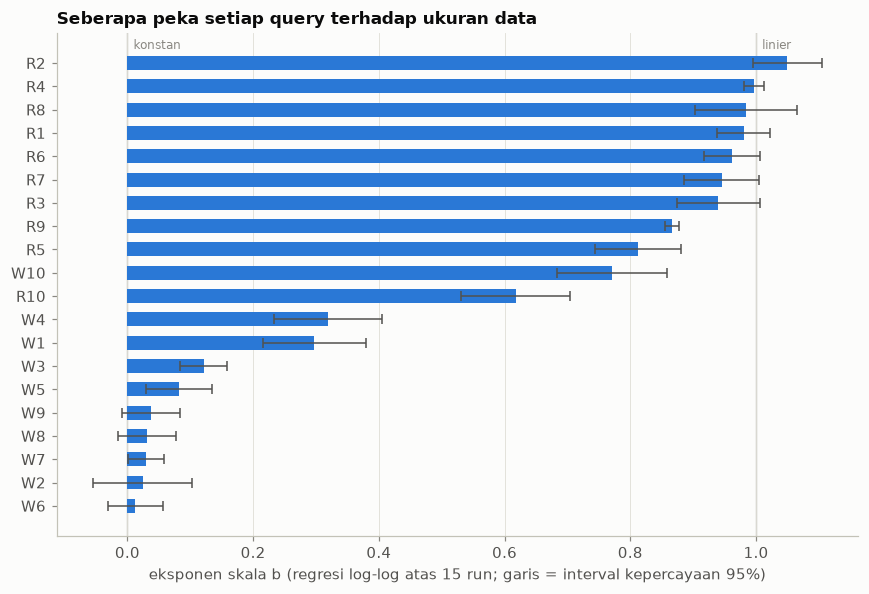

In [15]:
ordered = exponent.sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(range(len(ordered)), ordered.values, color=BLUE, height=0.6, zorder=2)
ax.errorbar(ordered.values, range(len(ordered)), xerr=[fits[q]['ci'] for q in ordered.index], fmt='none',
            ecolor=INK_2, elinewidth=1, capsize=3, zorder=3)
ax.set_yticks(range(len(ordered)), labels=ordered.index)
for x, label in [(0, 'konstan'), (1, 'linier')]:
    ax.axvline(x, color=MUTED, lw=0.8, zorder=1)
    ax.annotate(label, (x, len(ordered) - 0.4), xytext=(4, 0), textcoords='offset points', fontsize=8, color=MUTED)
ax.grid(axis='y', visible=False)
ax.set_xlabel('eksponen skala b (regresi log-log atas 15 run; garis = interval kepercayaan 95%)')
ax.set_title('Seberapa peka setiap query terhadap ukuran data')
fig.tight_layout()
plt.show()

In [16]:
no_growth = [q for q in QUERY_ORDER if fits[q]['b'] - fits[q]['ci'] <= 0 <= fits[q]['b'] + fits[q]['ci']]
linear = [q for q in QUERY_ORDER if fits[q]['b'] - fits[q]['ci'] <= 1 <= fits[q]['b'] + fits[q]['ci']]
lines = ['Dibaca secara statistik:']
if no_growth:
    lines.append(f'- **{names(no_growth)}:** interval kepercayaannya mencakup 0. Artinya, dari data ini waktunya '
                 '**tidak terbukti bertambah** saat data membesar 100 kali.')
if linear:
    lines.append(f'- **{names(linear)}:** interval kepercayaannya mencakup 1. Artinya, pertumbuhannya **tidak berbeda '
                 'nyata dari linier**: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.')
sublinear = [q for q in QUERY_ORDER if q not in no_growth + linear and fits[q]['b'] + fits[q]['ci'] < 1]
superlinear = [q for q in QUERY_ORDER if fits[q]['b'] - fits[q]['ci'] > 1]
if sublinear:
    lines.append(f'- **{names(sublinear)}:** berada di antara keduanya. Waktunya bertambah, tetapi lebih lambat dari '
                 'pertumbuhan data.')
if superlinear:
    lines.append(f'- **{names(superlinear)}:** intervalnya seluruhnya di atas 1. Waktunya bertambah **sedikit lebih '
                 'cepat dari pertumbuhan data**, jadi query ini yang paling perlu diawasi kalau data terus bertambah.')
say('\n'.join(lines))

Dibaca secara statistik:
- **W2, W6, W8 dan W9:** interval kepercayaannya mencakup 0. Artinya, dari data ini waktunya **tidak terbukti bertambah** saat data membesar 100 kali.
- **R1, R2, R3, R4, R6, R7 dan R8:** interval kepercayaannya mencakup 1. Artinya, pertumbuhannya **tidak berbeda nyata dari linier**: data 10 kali lebih besar, waktunya juga sekitar 10 kali lebih lama.
- **R5, R9, R10, W1, W3, W4, W5, W7 dan W10:** berada di antara keduanya. Waktunya bertambah, tetapi lebih lambat dari pertumbuhan data.

**Kira-kira kapan batasnya terlewati?** Kalau tren dari medium ke large terus berlanjut, kita bisa memperkirakan di ukuran data berapa setiap query mulai melewati targetnya. Ini perkiraan kasar, bukan hasil pengukuran, tetapi cukup untuk tahu mana yang perlu diperhatikan lebih dulu.

In [17]:
local_b = (wide['large'] / wide['medium']).map(math.log10)


def breaking_point(query):
    b, worst = local_b[query], large.loc[query, 'median_ms']
    if b < 0.3:
        return 'tidak terlewati (konstan)'
    orders = ORDERS['large'] * (large.loc[query, 'slo_ms'] / worst) ** (1 / b)
    text = f'≈ {orders / 1e6:,.1f} jt order'
    return text + ' (sudah terlewati di large)' if orders < ORDERS['large'] else text


breaking = pd.DataFrame({
    'kategori': large['category'],
    'median large (ms)': large['median_ms'].round(1),
    'target (ms)': large['slo_ms'],
    'b medium → large': local_b.round(2),
    'perkiraan batas target': [breaking_point(q) for q in large.index],
})
display(breaking.loc[[q for q in QUERY_ORDER if q in breaking.index]])

,kategori,median large (ms),target (ms),b medium → large,perkiraan batas target
query,,,,,
R1,Analitik,605.9,2000,1.05,≈ 3.1 jt order
R2,Analitik,1041.0,2000,1.15,≈ 1.8 jt order
R3,Analitik,1553.2,2000,0.76,≈ 1.4 jt order
R4,Analitik,603.9,2000,0.98,≈ 3.4 jt order
R5,Analitik,149.4,2000,0.62,≈ 65.5 jt order
R6,Analitik,849.4,2000,0.84,≈ 2.8 jt order
R7,Analitik,531.2,2000,0.79,≈ 5.3 jt order
R8,Analitik,584.2,2000,0.77,≈ 5.0 jt order
R9,Analitik,103.3,2000,0.87,≈ 30.4 jt order


In [18]:
estimates = {}
for query in QUERY_ORDER:
    if local_b[query] >= 0.3:
        estimates[query] = ORDERS['large'] * (large.loc[query, 'slo_ms'] / large.loc[query, 'median_ms']) ** (1 / local_b[query])
ranked = sorted(estimates.items(), key=lambda item: item[1])


def when(orders):
    return 'sudah terlewati di large' if orders < ORDERS['large'] else f'sekitar {orders_text(orders)}'


lines = ['Urutannya, dari yang paling cepat melewati batas:', '', '| Query | Perkiraan batas terlewati |', '|---|---|']
lines += [f'| {query} | {when(orders)} |' for query, orders in ranked[:4]]
constant = len(QUERY_ORDER) - len(estimates)
lines += ['', f'{constant} query lainnya hampir tidak terpengaruh ukuran data, jadi tidak akan melewati batasnya.']
say('\n'.join(lines))

Urutannya, dari yang paling cepat melewati batas:

| Query | Perkiraan batas terlewati |
|---|---|
| R3 | sekitar 1,4 juta order |
| R2 | sekitar 1,8 juta order |
| R6 | sekitar 2,8 juta order |
| R1 | sekitar 3,1 juta order |

7 query lainnya hampir tidak terpengaruh ukuran data, jadi tidak akan melewati batasnya.

## 5. Kepatuhan terhadap target

Bagian ini merangkum load test dan stress test dalam persentase:
- **Query yang melebihi target:** berapa persen query yang run paling lambatnya melewati target.
- **Run yang melebihi target:** berapa persen dari seluruh run yang diukur melewati target.
- **Bagian target yang terpakai:** seberapa besar bagian target yang sudah dipakai oleh run paling lambat di setiap kategori. Angka ini menunjukkan sisa ruang sebelum batas terlewati.

In [19]:
rows = []
for profile in PROFILES:
    frame = bench[bench['profile'] == profile]
    run_total = int(frame['times_ms'].map(len).sum())
    run_over = int(sum(sum(t > slo for t in times) for times, slo in zip(frame['times_ms'], frame['slo_ms'])))
    query_over = int((~frame['passes']).sum())
    used = 100 * frame['max_ms'] / frame['slo_ms']
    row = {'ukuran data': profile,
           'query melebihi target': f'{query_over}/{len(frame)} ({100 * query_over / len(frame):.0f}%)',
           'run melebihi target': f'{run_over}/{run_total} ({100 * run_over / run_total:.0f}%)'}
    for category_name in ['Analitik', 'Operasional', 'Transaksional']:
        part = frame[frame['category'] == category_name]
        row[f'terpakai maks: {category_name.lower()}'] = f"{100 * (part['max_ms'] / part['slo_ms']).max():.0f}%"
    above_half = frame[used >= 50]
    row['query ≥ 50% target'] = ', '.join(
        f"{q} ({u:.0f}%)" for q, u in zip(above_half['query'], used[used >= 50])) or '-'
    rows.append(row)
compliance = pd.DataFrame(rows).set_index('ukuran data')
display(compliance)

all_runs = int(bench['times_ms'].map(len).sum())
all_over = int(sum(sum(t > slo for t in times) for times, slo in zip(bench['times_ms'], bench['slo_ms'])))
normal_used = 100 * (bench.loc[bench['profile'] != 'large', 'max_ms']
                     / bench.loc[bench['profile'] != 'large', 'slo_ms']).max()
large_frame = bench[bench['profile'] == 'large']
large_used = 100 * large_frame['max_ms'] / large_frame['slo_ms']
watch = large_frame[large_used >= 50]
lines = [f'Dari {all_runs} run yang diukur di ketiga ukuran data, **{all_over} run ({100 * all_over / all_runs:.0f}%) '
         'melebihi target**.',
         f'- **Small dan medium:** run paling lambat paling banyak memakai {normal_used:.0f}% dari targetnya, jadi '
         'ruangnya masih sangat longgar.']
if watch.empty:
    lines.append('- **Large:** semua query masih memakai kurang dari separuh targetnya.')
else:
    lines.append('- **Large:** ruangnya mulai menyempit. '
                 + names(f"{q} ({u:.0f}%)" for q, u in zip(watch['query'], large_used[large_used >= 50]))
                 + ' sudah memakai separuh atau lebih dari targetnya, sedangkan query lain masih di bawah 50%. '
                 'Query inilah yang pertama perlu diperhatikan kalau datanya terus bertambah.')
say('\n'.join(lines))

,query melebihi target,run melebihi target,terpakai maks: analitik,terpakai maks: operasional,terpakai maks: transaksional,query ≥ 50% target
ukuran data,,,,,,
small,0/20 (0%),0/100 (0%),1%,0%,4%,-
medium,0/20 (0%),0/100 (0%),14%,1%,5%,-
large,0/20 (0%),0/100 (0%),81%,7%,29%,"R2 (62%), R3 (81%)"


Dari 300 run yang diukur di ketiga ukuran data, **0 run (0%) melebihi target**.
- **Small dan medium:** run paling lambat paling banyak memakai 14% dari targetnya, jadi ruangnya masih sangat longgar.
- **Large:** ruangnya mulai menyempit. R2 (62%) dan R3 (81%) sudah memakai separuh atau lebih dari targetnya, sedangkan query lain masih di bawah 50%. Query inilah yang pertama perlu diperhatikan kalau datanya terus bertambah.

## 6. Kenapa ada yang melambat, dan kenapa ada yang tetap cepat?

Saat pemanasan, benchmark juga mencatat *query plan*, yaitu langkah-langkah yang dipilih PostgreSQL untuk menjalankan sebuah query. Dari situ kita bisa melihat penyebabnya. Kolom yang perlu dilihat:
- **Seq scan:** tabel yang terpaksa dibaca dari awal sampai akhir. Ini yang paling penting.
- **Index scan:** berapa kali query bisa langsung melompat ke baris yang dicari.
- **Temp ditulis:** data yang tidak muat di memori kerja (4 MB per operasi), sehingga harus ditulis sementara ke disk.

In [20]:
plans = large[['category', 'seq_scan', 'index_scans', 'workers', 'data_read_mb', 'temp_written_mb', 'median_ms']].copy()
plans.columns = ['kategori', 'seq scan (dibaca seluruhnya)', 'index scan', 'worker paralel', 'data dibaca (MB)',
                 'temp ditulis (MB)', 'median (ms)']
display(plans.loc[[q for q in QUERY_ORDER if q in plans.index]].round(1))

,kategori,seq scan (dibaca seluruhnya),index scan,worker paralel,data dibaca (MB),temp ditulis (MB),median (ms)
query,,,,,,,
R1,Analitik,"driver_assignments, driver_partners, vehicles",0,2,196.8,21.0,605.9
R2,Analitik,"driver_assignments, driver_partners, trips, vehicles",0,2,289.8,127.4,1041.0
R3,Analitik,"driver_assignments, trips, vehicles",0,2,274.7,102.5,1553.2
R4,Analitik,trips,1,2,721.9,0.0,603.9
R5,Analitik,"locations, service_areas, trips",0,2,115.1,0.0,149.4
R6,Analitik,"locations, service_areas, trips",2,2,619.7,73.8,849.4
R7,Analitik,"payments, service_orders",0,2,153.8,133.0,531.2
R8,Analitik,"food_orders, locations, merchant_outlets, payments, service_areas, service_orders",0,2,203.0,19.7,584.2
R9,Analitik,"food_orders, locations, merchant_outlets, service_areas, service_orders",0,1,147.3,0.0,103.3


Bedanya kira-kira seperti mencari satu kata di buku tebal.
- **Tanpa index:** kita harus membaca dari halaman pertama sampai ketemu, jadi makin tebal bukunya, makin lama.
- **Dengan index:** kita cukup membuka daftar indeks di belakang dan langsung menuju halamannya, jadi tebal buku hampir tidak berpengaruh.

In [21]:
analytic_large = large[large['category'] == 'Analitik']
spill = analytic_large.sort_values('temp_written_mb', ascending=False).head(2)
writes_large = large[large['category'] == 'Transaksional']
flat = [q for q in writes_large.index if exponent[q] < 0.2]
slow_growth = [q for q in writes_large.index if 0.2 <= exponent[q] <= 0.5]
growing = [q for q in writes_large.index if exponent[q] > 0.5]
lines = ['Itulah yang terjadi di sini:',
         '- **Query analitik R1–R9 membaca seluruh tabel,** karena tugasnya memang merangkum semua data. Di large, '
         'sebagian juga harus menulis data sementara ke disk karena memori kerjanya tidak cukup, misalnya '
         + names(f"{q} sekitar {v:,.0f} MB".replace(',', '.') for q, v in spill['temp_written_mb'].items()) + '.']
example = ' Contohnya W5 dan W8, yang mencari baris lewat index `driver_assignments(trip_id)` dan `trips(order_id)`.' \
    if {'W5', 'W8'} <= set(flat) else ''
lines.append(f"- **{names(flat)} hampir tidak terpengaruh ukuran data,** karena membaca dan menulis lewat index atau "
             f"primary key. Di large pun paling lama {ms_text(writes_large.loc[flat, 'max_ms'].max())}.{example}")
if slow_growth:
    lines.append(f"- **{names(slow_growth)} tumbuh pelan:** " + names(
        f"{q} sekitar {ms_text(large.loc[q, 'median_ms'])}" for q in slow_growth) + ' di large.')
for q in growing:
    tables = [name for name in large.loc[q, 'seq_scan'].split(', ') if name not in ('service_areas', '-')]
    verdict = 'masih jauh di bawah' if large.loc[q, 'passes'] else 'sudah melewati'
    lines.append(f"- **{q} ikut melambat** (sekitar {ms_text(large.loc[q, 'median_ms'])} di large), karena masih "
                 f"membaca seluruh tabel {names('`' + name + '`' for name in tables)}. Waktu itu {verdict} target "
                 f"{ms_text(large.loc[q, 'slo_ms'])}.")
say('\n'.join(lines))

Itulah yang terjadi di sini:
- **Query analitik R1–R9 membaca seluruh tabel,** karena tugasnya memang merangkum semua data. Di large, sebagian juga harus menulis data sementara ke disk karena memori kerjanya tidak cukup, misalnya R7 sekitar 133 MB dan R2 sekitar 127 MB.
- **W2, W3, W5, W6, W7, W8 dan W9 hampir tidak terpengaruh ukuran data,** karena membaca dan menulis lewat index atau primary key. Di large pun paling lama 4,3 ms. Contohnya W5 dan W8, yang mencari baris lewat index `driver_assignments(trip_id)` dan `trips(order_id)`.
- **W1 dan W4 tumbuh pelan:** W1 sekitar 20 ms dan W4 sekitar 13 ms di large.
- **W10 ikut melambat** (sekitar 46 ms di large), karena masih membaca seluruh tabel `food_orders`. Waktu itu masih jauh di bawah target 200 ms.

## 7. Standar deviasi: seberapa konsisten waktunya?

Kalau query yang sama dijalankan lima kali, waktunya tidak akan persis sama.
- **Standar deviasi:** rata-rata seberapa jauh setiap run meleset dari rata-ratanya, dalam milidetik. Makin kecil standar deviasinya, makin konsisten.
- **Koefisien variasi:** standar deviasi dibagi rata-rata, ditulis dalam persen. Ini kita perlukan karena query kita ada yang 0,3 ms dan ada yang 1,5 detik, sehingga standar deviasi dalam milidetik tidak bisa dibandingkan begitu saja.

Patokan koefisien variasi yang dipakai:

| Koefisien variasi | Artinya |
|---|---|
| di bawah 5% | sangat konsisten |
| 5–15% | masih wajar |
| di atas 15% | perlu dilihat lebih dekat |

Tabel berikut menulis setiap hasil sebagai rata-rata ± standar deviasi (koefisien variasi), dalam milidetik.

In [22]:
def short(value):
    return f'{value:,.0f}' if value >= 100 else f'{value:,.1f}' if value >= 10 else f'{value:.2f}'


sd = bench.copy()
sd['hasil'] = [f'{short(m)} ± {short(s)} ({cv:.0f}%)' for m, s, cv in zip(sd['mean_ms'], sd['stdev_ms'], sd['cv_pct'])]
sd_table = sd.pivot_table(index=['category', 'query'], columns='profile', values='hasil', aggfunc='first',
                          observed=True)
sd_table.index.names = ['kategori', 'query']
sd_table.columns = [f'{p} (ms)' for p in sd_table.columns]
display(sd_table)

bands = pd.cut(bench['cv_pct'], [0, 5, 15, float('inf')], labels=['< 5%', '5–15%', '> 15%'], right=False)
count = pd.crosstab([bench['category']], bands).reindex(columns=['< 5%', '5–15%', '> 15%'], fill_value=0)
count.index.name = 'kategori'
count.columns.name = 'koefisien variasi'
display(Markdown('**Jumlah hasil per kelompok koefisien variasi** (20 query × 3 ukuran data = 60 hasil)'))
display(count)

small (ms)        medium (ms)         large (ms)
kategori      query                                                         
Analitik      R1      6.94 ± 0.12 (2%)  53.6 ± 5.42 (10%)   639 ± 88.5 (14%)
              R2     8.62 ± 1.31 (15%)  71.5 ± 6.89 (10%)  1,079 ± 90.9 (8%)
              R3      20.4 ± 0.37 (2%)    276 ± 10.7 (4%)  1,551 ± 52.3 (3%)
              R4      6.13 ± 0.10 (2%)   64.7 ± 4.90 (8%)    605 ± 13.5 (2%)
              R5      3.53 ± 0.14 (4%)   35.9 ± 1.80 (5%)    149 ± 4.95 (3%)
              R6      10.2 ± 0.13 (1%)   123 ± 13.6 (11%)    853 ± 13.8 (2%)
              R7      6.83 ± 0.17 (2%)   88.3 ± 8.13 (9%)    530 ± 7.79 (1%)
              R8      6.24 ± 0.25 (4%)    103 ± 7.99 (8%)    580 ± 13.8 (2%)
              R9      1.90 ± 0.08 (4%)   14.2 ± 0.60 (4%)    103 ± 3.47 (3%)
Operasional   R10    0.38 ± 0.06 (17%)   0.92 ± 0.05 (5%)  6.54 ± 0.65 (10%)
Transaksional W1     4.92 ± 1.23 (25%)  6.92 ± 2.04 (29%)   19.0 ± 1.75 (9%)
              W2     1.01 ± 0.35 (35%)   0.84 ± 0.07 (8%)  1.10 ± 0.30 (27%)
              W3      1.02 ± 0.07 (7%)   1.16 ± 0.02 (2%)  1.81 ± 0.32 (18%)
              W4     3.05 ± 0.39 (13%)   3.68 ± 0.28 (8%)   13.2 ± 0.83 (6%)
              W5     1.53 ± 0.17 (11%)  1.50 ± 0.14 (10%)  2.26 ± 0.55 (24%)
              W6      1.70 ± 0.10 (6%)  1.44 ± 0.14 (10%)  1.81 ± 0.30 (16%)
              W7      3.17 ± 0.26 (8%)  3.18 ± 0.33 (10%)  3.64 ± 0.38 (10%)
              W8     1.52 ± 0.15 (10%)  1.44 ± 0.21 (15%)  1.77 ± 0.33 (19%)
              W9      2.12 ± 0.20 (9%)  2.44 ± 0.30 (12%)  2.57 ± 0.62 (24%)
              W10     1.37 ± 0.06 (4%)   4.75 ± 0.43 (9%)  48.3 ± 8.64 (18%)

**Jumlah hasil per kelompok koefisien variasi** (20 query × 3 ukuran data = 60 hasil)

koefisien variasi,< 5%,5–15%,> 15%
kategori,,,
Analitik,17,9,1
Operasional,0,2,1
Transaksional,2,18,10


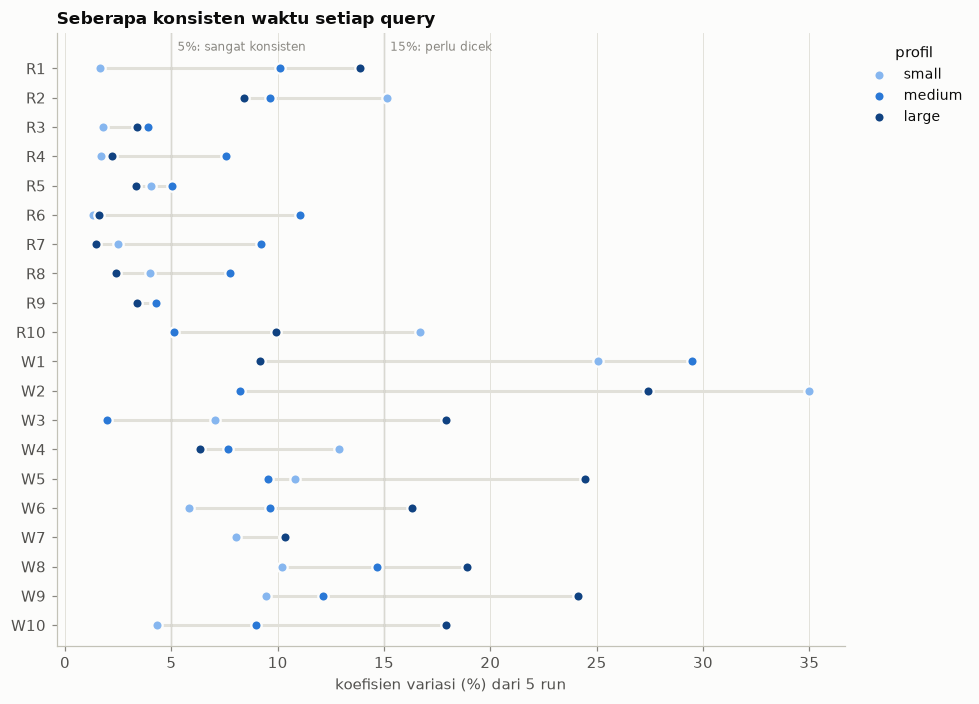

In [23]:
PROFILE_COLORS = {'small': '#86b6ef', 'medium': '#2a78d6', 'large': '#104281'}
order = list(reversed(QUERY_ORDER))
fig, ax = plt.subplots(figsize=(9, 6.5))
for y, query in enumerate(order):
    values = bench[bench['query'] == query].set_index('profile')['cv_pct']
    ax.plot([values.min(), values.max()], [y, y], color=GRID, lw=2, zorder=1)
    for profile in PROFILES:
        ax.scatter(values[profile], y, s=46, color=PROFILE_COLORS[profile], edgecolor=SURFACE, lw=1.5, zorder=3,
                   label=profile if y == 0 else None)
for x, label in [(5, '5%: sangat konsisten'), (15, '15%: perlu dicek')]:
    ax.axvline(x, color=MUTED, lw=0.8, zorder=1)
    ax.annotate(label, (x, len(order) - 0.4), xytext=(4, 0), textcoords='offset points', fontsize=8, color=MUTED)
ax.set_yticks(range(len(order)), labels=order)
ax.set_ylim(-0.7, len(order) + 0.2)
ax.grid(axis='y', visible=False)
ax.set_xlabel('koefisien variasi (%) dari 5 run')
ax.set_title('Seberapa konsisten waktu setiap query')
ax.legend(title='profil', loc='upper left', bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

Grafik berikut menjelaskan kenapa query yang cepat sering terlihat "goyang".
- **Setiap titik:** satu hasil, yaitu satu query di satu ukuran data. Posisinya adalah rata-rata waktu dan standar deviasinya, dalam milidetik.
- **Dua garis miring:** koefisien variasi 5% dan 15%.
- **Cara membacanya:** titik di atas garis 15% terlihat tidak konsisten kalau diukur dalam persen. Tetapi lihat sumbu tegaknya: untuk query yang cepat, penyimpangannya hanya sepersekian milidetik.

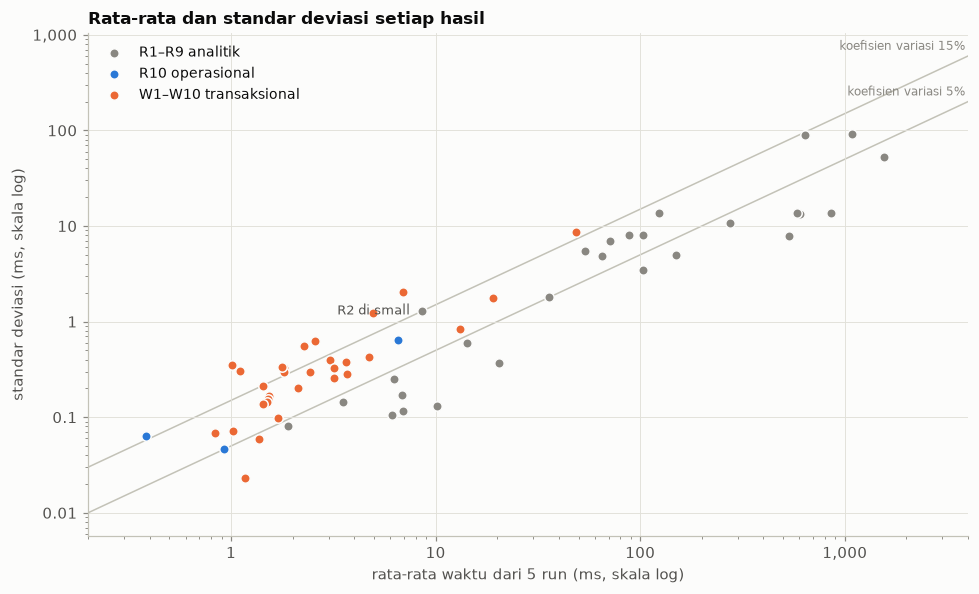

In [24]:
CATEGORY_STYLE = {'Analitik': ('#898781', 'R1–R9 analitik'), 'Operasional': (BLUE, 'R10 operasional'),
                  'Transaksional': (ORANGE, 'W1–W10 transaksional')}
fig, ax = plt.subplots(figsize=(9, 5.5))
xs = [0.2, 4000]
for cv in (5, 15):
    ax.plot(xs, [x * cv / 100 for x in xs], color=AXIS, lw=1, zorder=1)
    ax.annotate(f'koefisien variasi {cv}%', (xs[1], xs[1] * cv / 100), xytext=(-2, 4), textcoords='offset points', ha='right',
                fontsize=8, color=MUTED)
for category_name, (color, label) in CATEGORY_STYLE.items():
    frame = bench[bench['category'] == category_name]
    ax.scatter(frame['mean_ms'], frame['stdev_ms'], s=38, color=color, edgecolor=SURFACE, lw=1, zorder=3, label=label)
for _, row in bench[(bench['cv_pct'] > 15) & (bench['category'] == 'Analitik')].iterrows():
    ax.annotate(f"{row['query']} di {row['profile']}", (row['mean_ms'], row['stdev_ms']), xytext=(-8, 0),
                textcoords='offset points', ha='right', va='center', fontsize=8.5, color=INK_2)
ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_formatter(PLAIN)
ax.yaxis.set_major_formatter(PLAIN)
ax.set_xlim(0.2, 4000)
ax.set_xlabel('rata-rata waktu dari 5 run (ms, skala log)')
ax.set_ylabel('standar deviasi (ms, skala log)')
ax.set_title('Rata-rata dan standar deviasi setiap hasil')
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

Hasil dengan koefisien variasi di atas 15% kita lihat lebih dekat. Tabel ini menampilkan kelima run-nya, berikut selisih run paling lambat dari median, supaya terlihat seberapa besar penyimpangannya dalam milidetik.

In [25]:
spread = bench[bench['cv_pct'] > 15].copy()
spread['5 run (ms)'] = spread['times_ms'].map(lambda times: ', '.join(short(t) for t in times))
spread['selisih terlambat − median (ms)'] = (spread['max_ms'] - spread['median_ms']).map(short)
spread['koefisien variasi'] = spread['cv_pct'].map('{:.0f}%'.format)
spread = spread[['profile', 'query', 'category', '5 run (ms)', 'selisih terlambat − median (ms)', 'koefisien variasi']]
spread.columns = ['profil', 'query', 'kategori', '5 run (ms)', 'selisih terlambat − median (ms)', 'koefisien variasi']
display(spread.set_index(['profil', 'query']))

kategori                    5 run (ms)  \
profil query                                                
small  R2          Analitik  10.9, 8.42, 7.92, 7.94, 7.90   
       R10      Operasional  0.48, 0.35, 0.35, 0.42, 0.32   
       W1     Transaksional  4.14, 4.50, 7.09, 4.20, 4.67   
       W2     Transaksional  1.01, 0.68, 1.53, 1.13, 0.69   
medium W1     Transaksional  9.94, 4.81, 7.28, 7.30, 5.26   
large  W2     Transaksional  1.43, 0.96, 1.43, 0.79, 0.92   
       W3     Transaksional  2.34, 1.52, 1.60, 1.84, 1.73   
       W5     Transaksional  2.15, 1.99, 3.24, 1.97, 1.96   
       W6     Transaksional  1.51, 2.10, 2.15, 1.56, 1.76   
       W8     Transaksional  1.46, 1.81, 1.76, 2.30, 1.50   
       W9     Transaksional  2.23, 2.23, 2.89, 3.50, 1.99   
       W10    Transaksional  58.1, 42.7, 56.4, 45.7, 38.4   

             selisih terlambat − median (ms) koefisien variasi  
profil query                                                    
small  R2                               2.99               15%  
       R10                              0.13               17%  
       W1                               2.59               25%  
       W2                               0.51               35%  
medium W1                               2.67               29%  
large  W2                               0.47               27%  
       W3                               0.61               18%  
       W5                               1.25               24%  
       W6                               0.39               16%  
       W8                               0.54               19%  
       W9                               1.27               24%  
       W10                              12.4               18%

In [26]:
analytic = bench[bench['category'] == 'Analitik']
fast = bench[bench['mean_ms'] < 10]
max_dev_fast = (fast['max_ms'] - fast['median_ms']).max()
strays = analytic[analytic['cv_pct'] > 15]
lines = ['Secara umum, angkanya bisa dipercaya.',
         f"- **Query analitik konsisten:** {int((analytic['cv_pct'] < 15).sum())} dari {len(analytic)} hasilnya punya "
         f"koefisien variasi di bawah 15%, dan {int((analytic['cv_pct'] < 5).sum())} di antaranya di bawah 5%.",
         '- **Query yang sangat cepat hanya terlihat "goyang" dalam persen.** Untuk query yang rata-ratanya di bawah '
         f'10 ms, run paling lambat paling banyak meleset {ms_text(max_dev_fast)} dari median. Gangguan sekecil apa pun '
         'dari sistem sudah cukup untuk membuatnya terlihat besar dalam persen, padahal kenyataannya tidak terasa.']
if strays.empty:
    lines.append('- **Tidak ada hasil analitik yang benar-benar menyimpang.**')
else:
    lines.append(f'- **Ada {len(strays)} hasil analitik yang menyimpang:**')
    for _, row in strays.iterrows():
        runs_text = names(f'{t:,.0f}'.replace(',', '.') for t in row['times_ms'])
        lines.append(f"  - **{row['query']} di {row['profile']}:** kelima run-nya {runs_text} ms.")
    lines.append('\n  ' + ('Pada hasil ini' if len(strays) == 1 else 'Pada hasil-hasil ini')
                 + ', sebagian besar run-nya berdekatan, dan hanya satu atau dua run yang jauh lebih lambat. Pola seperti '
                 'ini biasanya datang dari aktivitas lain di mesin pada saat itu, bukan dari query-nya.')
lines.append('\nInilah alasan kita memakai median untuk melihat tren, dan run paling lambat untuk mengecek target. '
             'Dengan begitu, penyimpangan seperti ini tidak sampai membuat kesimpulan kita terlalu optimis.')
say('\n'.join(lines))

Secara umum, angkanya bisa dipercaya.
- **Query analitik konsisten:** 26 dari 27 hasilnya punya koefisien variasi di bawah 15%, dan 17 di antaranya di bawah 5%.
- **Query yang sangat cepat hanya terlihat "goyang" dalam persen.** Untuk query yang rata-ratanya di bawah 10 ms, run paling lambat paling banyak meleset 3,0 ms dari median. Gangguan sekecil apa pun dari sistem sudah cukup untuk membuatnya terlihat besar dalam persen, padahal kenyataannya tidak terasa.
- **Ada 1 hasil analitik yang menyimpang:**
  - **R2 di small:** kelima run-nya 11, 8, 8, 8 dan 8 ms.

  Pada hasil ini, sebagian besar run-nya berdekatan, dan hanya satu atau dua run yang jauh lebih lambat. Pola seperti ini biasanya datang dari aktivitas lain di mesin pada saat itu, bukan dari query-nya.

Inilah alasan kita memakai median untuk melihat tren, dan run paling lambat untuk mengecek target. Dengan begitu, penyimpangan seperti ini tidak sampai membuat kesimpulan kita terlalu optimis.

## 8. Error rate

Error rate adalah persentase eksekusi yang gagal. Kita bisa menghitungnya dengan pasti karena benchmark diatur untuk langsung berhenti begitu ada satu statement yang error, tanpa menyimpan hasil apa pun. Jadi hasil yang lengkap, yaitu lima run untuk setiap query, berarti semua eksekusinya berhasil.

In [27]:
complete = bench['times_ms'].map(len) == bench['profile'].map(TIMED_RUNS)
errors = bench.assign(failed=~complete).groupby('profile', observed=True).agg(
    query=('query', 'count'), gagal=('failed', 'sum'))
errors['eksekusi per query'] = [EXECUTIONS[p] for p in errors.index]
errors['total eksekusi'] = errors['query'] * errors['eksekusi per query']
errors['eksekusi gagal'] = errors['gagal'] * errors['eksekusi per query']
errors['error rate'] = (100 * errors['eksekusi gagal'] / errors['total eksekusi']).map('{:.0f}%'.format)
table = errors[['query', 'eksekusi per query', 'total eksekusi', 'eksekusi gagal', 'error rate']].astype(str)
table.index = table.index.astype(str)
total_runs, total_failed = errors['total eksekusi'].sum(), errors['eksekusi gagal'].sum()
table.loc['total'] = [str(errors['query'].sum()), '', str(total_runs), str(total_failed),
                      f'{100 * total_failed / total_runs:.0f}%']
table.index.name = 'profil'
display(table)

,query,eksekusi per query,total eksekusi,eksekusi gagal,error rate
profil,,,,,
small,20,6,120,0,0%
medium,20,6,120,0,0%
large,20,6,120,0,0%
total,60,,360,0,0%


In [28]:
say(f"Hasilnya: dari {total_runs} eksekusi, **{total_failed} gagal**, jadi error rate-nya "
    f"**{100 * total_failed / total_runs:.0f}%**.")

Hasilnya: dari 360 eksekusi, **0 gagal**, jadi error rate-nya **0%**.

Tapi tidak error belum tentu berhasil. Sebuah write bisa saja berjalan tanpa error tetapi tidak mengubah apa-apa, misalnya `UPDATE` yang tidak menemukan baris yang dicari. Karena itu, kita cek juga berapa baris yang diubah setiap write, di setiap run dan setiap ukuran data.

In [29]:
writes = bench[bench['category'] == 'Transaksional']
changed = writes.pivot_table(index='query', columns='profile', values='rows', observed=True)[PROFILES].astype(int)
changed.columns = [f'baris diubah ({p})' for p in PROFILES]
same_runs = writes.groupby('query', observed=True)['rows_per_run'].agg(lambda runs: all(len(set(r)) == 1 for r in runs))
changed['sama di semua run'] = same_runs.map({True: '✓', False: '✗'})
changed['sama di semua profil'] = (changed.iloc[:, :3].nunique(axis=1) == 1).map({True: '✓', False: '✗'})
display(changed)

,baris diubah (small),baris diubah (medium),baris diubah (large),sama di semua run,sama di semua profil
query,,,,,
W1,4,4,4,✓,✓
W2,1,1,1,✓,✓
W3,3,3,3,✓,✓
W4,6,6,6,✓,✓
W5,3,3,3,✓,✓
W6,6,6,6,✓,✓
W7,8,8,8,✓,✓
W8,3,3,3,✓,✓
W9,7,7,7,✓,✓


In [30]:
mismatch = changed[(changed['sama di semua run'] != '✓') | (changed['sama di semua profil'] != '✓')]
say('Jumlah baris yang diubah sama persis di setiap run dan setiap ukuran data. Artinya, setiap write benar-benar '
    'mengerjakan hal yang sama setiap kali dijalankan.' if mismatch.empty else
    'Ada write yang jumlah baris diubahnya berbeda: ' + names(mismatch.index) + '. Ini perlu diperiksa.')

Jumlah baris yang diubah sama persis di setiap run dan setiap ukuran data. Artinya, setiap write benar-benar mengerjakan hal yang sama setiap kali dijalankan.

## 9. Kesimpulan

Grafik ini merangkum hasil di ukuran data terbesar. Setiap batang menunjukkan berapa persen dari target yang sudah dipakai oleh run paling lambat setiap query. Semakin panjang batangnya, semakin dekat query itu ke batasnya.

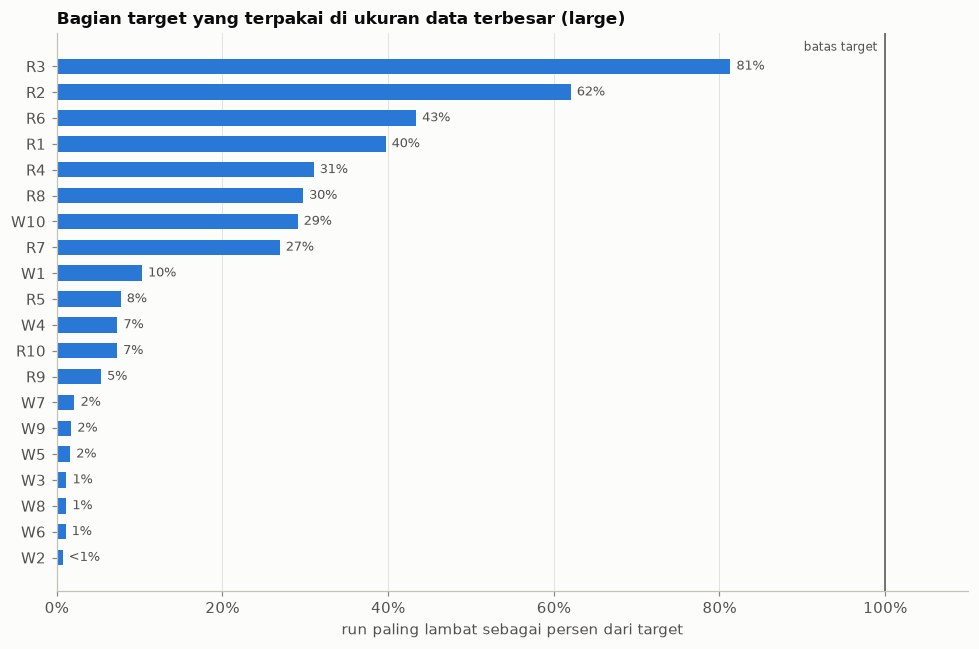

In [31]:
summary_large = bench[bench['profile'] == 'large'].assign(
    pct=lambda f: 100 * f['max_ms'] / f['slo_ms']).sort_values('pct')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(summary_large['query'].astype(str), summary_large['pct'], color=BLUE, height=0.6, zorder=2)
for y, pct in enumerate(summary_large['pct']):
    label = '<1%' if pct < 1 else f'{pct:.0f}%'
    ax.annotate(label, (pct, y), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8.5, color=INK_2)
ax.axvline(100, color=INK_2, lw=1, zorder=3)
ax.annotate('batas target', (100, len(summary_large) - 0.4), xytext=(-5, 0), textcoords='offset points',
            ha='right', fontsize=8, color=INK_2)
ax.set_xlim(0, 110)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.grid(axis='y', visible=False)
ax.set_xlabel('run paling lambat sebagai persen dari target')
ax.set_title('Bagian target yang terpakai di ukuran data terbesar (large)')
fig.tight_layout()
plt.show()

In [32]:
closest_row = bench.loc[(bench['max_ms'] / bench['slo_ms']).idxmax()]
closest_query = str(closest_row['query'])
estimate = estimates.get(closest_query)
slowest_write = writes_large['max_ms'].idxmax()
failed_all = bench[~bench['passes']]
lines = ['- **Semua query lulus target** di ketiga ukuran data.' if failed_all.empty else
         f'- **{len(failed_all)} hasil tidak lulus target:** '
         + names(f"{r['query']} di {r['profile']}" for _, r in failed_all.iterrows()) + '.',
         ('- **Query analitik paling peka terhadap ukuran data.** ' + (
             f"Yang paling berat adalah {closest_query}: run paling lambatnya {ms_text(closest_row['max_ms'])}, "
             f"melewati batas {ms_text(closest_row['slo_ms'])} di {closest_row['profile']}."
             if closest_row['max_ms'] > closest_row['slo_ms'] else
             f"Yang paling dekat ke batas adalah {closest_query}, dengan {ms_text(closest_row['max_ms'])} dari batas "
             f"{ms_text(closest_row['slo_ms'])} di {closest_row['profile']}"
             + (f", dan diperkirakan melewati batas di sekitar {orders_text(estimate)}."
                if estimate and estimate > ORDERS['large'] else '.'))),
         f"- **Query yang memakai index tetap cepat,** berapa pun ukuran datanya. R10 butuh {ms_text(large.loc['R10', 'max_ms'])} "
         f"di large, dan write paling lambat ({slowest_write}) hanya {ms_text(writes_large.loc[slowest_write, 'max_ms'])} "
         f"dari target {ms_text(writes_large.loc[slowest_write, 'slo_ms'])}.",
         f"- **Hasilnya bisa dipercaya:** konsisten dari run ke run, dan "
         + ('tanpa error.' if total_failed == 0 else f'{total_failed} eksekusi gagal.'),
         '',
         '**Saran:** kalau data tumbuh jauh di atas 1 juta order, siapkan *materialized view* untuk dashboard.',
         '',
         '*Uji ini memakai satu pengguna di satu mesin. Target waktu dan titik patah di atas bersifat perkiraan.*']
say('\n'.join(lines))

- **Semua query lulus target** di ketiga ukuran data.
- **Query analitik paling peka terhadap ukuran data.** Yang paling dekat ke batas adalah R3, dengan 1,6 detik dari batas 2 detik di large, dan diperkirakan melewati batas di sekitar 1,4 juta order.
- **Query yang memakai index tetap cepat,** berapa pun ukuran datanya. R10 butuh 7,3 ms di large, dan write paling lambat (W10) hanya 58 ms dari target 200 ms.
- **Hasilnya bisa dipercaya:** konsisten dari run ke run, dan tanpa error.

**Saran:** kalau data tumbuh jauh di atas 1 juta order, siapkan *materialized view* untuk dashboard.

*Uji ini memakai satu pengguna di satu mesin. Target waktu dan titik patah di atas bersifat perkiraan.*

### Cara menjalankan ulang

1. Jalankan `scripts/benchmark.py` untuk ketiga ukuran data (lihat `scripts/README.md`).
2. Jalankan `uv sync --group notebook`.
3. Buka notebook ini di VS Code dengan kernel `.venv`, atau jalankan dari root repo:

```bash
uv run --group notebook jupyter nbconvert --to notebook --execute --inplace notebook/volume_test.ipynb
```

Notebook selalu membaca hasil terbaru di `results/`.